# QMed — Quantum ML
### SIH 2026 · PS SIH26139 · Team: Dark-47


---

1. Download the Cleveland heart disease dataset (303 patients).  
2. Run a standard model → obtain a result.  
3. Run a **quantum** model → obtain another result.  
4. Compare the two.

In [1]:
!pip install -q pennylane ucimlrepo

import numpy as np
import pandas as pd
import pennylane as qml

print("PennyLane version:", qml.__version__)
print("Setup complete.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 44.8 MB/s eta 0:00:00
PennyLane version: 0.45.1
Setup complete.


## Step 2 — Downloading the Data

**Cleveland Heart Disease** — 303 patients, 13 measurements (age, blood pressure, cholesterol, etc.), and a final outcome: presence or absence of heart disease.

**Primary Dataset** — Small, clean, and widely used in QML research, allowing results to be compared with those of others.

In [2]:
def load_cleveland():
    """Try three sources in order; use whichever works."""
    # Source 1 - official UCI python package
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=45)
        X = d.data.features.apply(pd.to_numeric, errors="coerce")
        y = (d.data.targets.iloc[:, 0].values > 0).astype(int)
        return X.values.astype(float), y, X.columns.tolist(), "UCI (ucimlrepo)"
    except Exception as e:
        print("Source 1 failed:", e)

    # Source 2 - direct file download
    try:
        url = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
               "heart-disease/processed.cleveland.data")
        cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
        df = pd.read_csv(url, names=cols, na_values="?")
        y = (df["target"].values > 0).astype(int)
        X = df.drop(columns="target")
        return X.values.astype(float), y, X.columns.tolist(), "UCI (direct)"
    except Exception as e:
        print("Source 2 failed:", e)

    # Source 3 - synthetic stand-in so the notebook still runs
    from sklearn.datasets import make_classification
    Xs, ys = make_classification(n_samples=300, n_features=13,
                                 n_informative=7, random_state=42)
    names = [f"feature_{i}" for i in range(13)]
    print("WARNING: real data unavailable, using synthetic data.")
    return Xs, ys, names, "synthetic fallback"


X, y, feature_names, source = load_cleveland()

print(f"Source        : {source}")
print(f"Patients      : {X.shape[0]}")
print(f"Features      : {X.shape[1]}")
print(f"Class balance : {np.bincount(y)}   (no disease / disease)")
print(f"\nFeatures: {feature_names}")

Source        : UCI (ucimlrepo)
Patients      : 303
Features      : 13
Class balance : [164 139]   (no disease / disease)

Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


## Step 3 — Standard (Classical) Model

This serves **benchmark**. Determine whether the quantum model performs well or poorly by comparing its results against this figure.

**What is a Pipeline?** It involves bundling data preparation steps together so that the model fits separately on each fold—ensuring **no data leakage** occurs. This is the most critical rule. If you prepare the data outside of a pipeline, your results will be invalid.

**What is AUC?** 0.5 = Random guessing. 1.0 = Perfect. Anything above 0.8 is considered good.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

N_QUBITS = 4               # number of qubits = number of PCA components
ANGLE_SCALE = np.pi / 4    # feature range; try pi/8 or pi/2 and compare


def prep_steps():
    """Identical preprocessing for every model. Fitted inside each CV
    fold, which is what prevents data leakage."""
    return [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=N_QUBITS, random_state=42)),
        ("angles", MinMaxScaler(feature_range=(0, ANGLE_SCALE))),
    ]


def evaluate(model, name, n_splits=5, seed=0, data=None):
    """Cross-validate one model. Reports train AND validation AUC —
    the gap between them is the overfitting measurement."""
    Xe, ye = data if data else (X, y)
    pipe = Pipeline(prep_steps() + [("clf", model)])
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    r = cross_validate(pipe, Xe, ye, cv=cv, scoring="roc_auc",
                       return_train_score=True)
    tr, va = r["train_score"].mean(), r["test_score"].mean()
    print(f"{name:<24} train {tr:.3f}   val {va:.3f}   gap {tr - va:+.3f}")
    return tr, va


print("CLASSICAL BASELINE\n" + "-" * 62)
evaluate(LogisticRegression(max_iter=2000), "Logistic Regression")
evaluate(SVC(C=1.0), "SVM (RBF kernel)")
evaluate(RandomForestClassifier(max_depth=4, random_state=0), "Random Forest")

print("\ngap > 0.10 means the model is memorising -> overfitting")

CLASSICAL BASELINE
--------------------------------------------------------------
Logistic Regression      train 0.908   val 0.904   gap +0.004
SVM (RBF kernel)         train 0.928   val 0.894   gap +0.034
Random Forest            train 0.968   val 0.894   gap +0.074

gap > 0.10 means the model is memorising -> overfitting


## Step 4 — Quantum Model (QSVM)

The concept is simple. Data from two patients is used to create two quantum states, and then the **degree of similarity** between these two states is measured. This similarity value is known as the **kernel**.

A table is constructed by calculating the similarity for every pair of patients, and this table is then fed into a standard SVM.

**Why I chose this:** This circuit involves **no learnable parameters**. Consequently, the risk of overfitting (memorization) is low. This makes it the safest quantum model for small datasets.

In [4]:
from sklearn.base import BaseEstimator, ClassifierMixin

dev = qml.device("default.qubit", wires=N_QUBITS)
wires = list(range(N_QUBITS))


def encode(x):
    """Angle encoding: each feature becomes a rotation angle."""
    for i, w in enumerate(wires):
        qml.RY(x[i], wires=w)


@qml.qnode(dev)
def kernel_circuit(x1, x2):
    """K(x1, x2) = |<phi(x1)|phi(x2)>|^2, read off as the probability
    of measuring the all-zero state."""
    encode(x1)
    qml.adjoint(encode)(x2)
    return qml.probs(wires=wires)


class QuantumKernelSVM(ClassifierMixin, BaseEstimator):
    """Quantum kernel estimation feeding a classical SVM.
    No trainable circuit parameters - only C is tuned."""

    def __init__(self, C=1.0):
        self.C = C

    def _kernel_matrix(self, A, B):
        same = A is B
        K = np.zeros((len(A), len(B)))
        for i in range(len(A)):
            for j in range(i if same else 0, len(B)):
                K[i, j] = kernel_circuit(A[i], B[j])[0]
                if same:
                    K[j, i] = K[i, j]
        return K

    def fit(self, X_, y_):
        self.X_ = np.asarray(X_, dtype=float)
        self.svm_ = SVC(kernel="precomputed", C=self.C)
        self.svm_.fit(self._kernel_matrix(self.X_, self.X_), y_)
        self.classes_ = self.svm_.classes_
        return self

    def decision_function(self, X_):
        K = self._kernel_matrix(np.asarray(X_, dtype=float), self.X_)
        return self.svm_.decision_function(K)

    def predict(self, X_):
        K = self._kernel_matrix(np.asarray(X_, dtype=float), self.X_)
        return self.svm_.predict(K)


# Quick check that the kernel behaves sensibly
a = np.array([0.1, 0.2, 0.3, 0.4])
b = np.array([0.7, 0.1, 0.6, 0.2])
print("Kernel sanity check")
print(f"  same patient      : {kernel_circuit(a, a)[0]:.4f}   (should be 1.0)")
print(f"  different patients: {kernel_circuit(a, b)[0]:.4f}   (should be lower)")

# Kernel matrix is O(n^2). 300 patients = 90,000 circuits, which is slow.
# Start with 120 patients; increase later once everything works.
rng = np.random.default_rng(0)
idx = rng.choice(len(X), size=min(120, len(X)), replace=False)
X_q, y_q = X[idx], y[idx]

print(f"\nRunning quantum model on {len(X_q)} patients (for speed)")
print("This takes 1-2 minutes...\n")
evaluate(QuantumKernelSVM(C=1.0), "QSVM (quantum kernel)",
         n_splits=3, data=(X_q, y_q))

Kernel sanity check
  same patient      : 1.0000   (should be 1.0)
  different patients: 0.8812   (should be lower)

Running quantum model on 120 patients (for speed)
This takes 1-2 minutes...

QSVM (quantum kernel)    train 0.937   val 0.933   gap +0.004


(np.float64(0.9371345029239766), np.float64(0.9331662489557226))

## Step 5 — Take a look at the circuit

Take a look at what the quantum circuit looks like. It involves just a few rotations—there is nothing to be afraid of.

In [5]:
sample = np.array([0.3, 0.5, 0.2, 0.7])
other = np.array([0.6, 0.1, 0.8, 0.2])
print(qml.draw(kernel_circuit)(sample, other))

0: ──RY(0.30)──RY(0.60)†─┤ ╭Probs
1: ──RY(0.50)──RY(0.10)†─┤ ├Probs
2: ──RY(0.20)──RY(0.80)†─┤ ├Probs
3: ──RY(0.70)──RY(0.20)†─┤ ╰Probs


## Step 6 — Comparison

All models are being run on the **data of the same 120 patients** — this ensures a fair comparison.

This is our first results table.

All models on the same 120 patients
--------------------------------------------------------------
Logistic Regression      train 0.939   val 0.931   gap +0.007
SVM (RBF)                train 0.961   val 0.901   gap +0.059
Random Forest            train 0.997   val 0.884   gap +0.113
QSVM (quantum)           train 0.937   val 0.933   gap +0.004


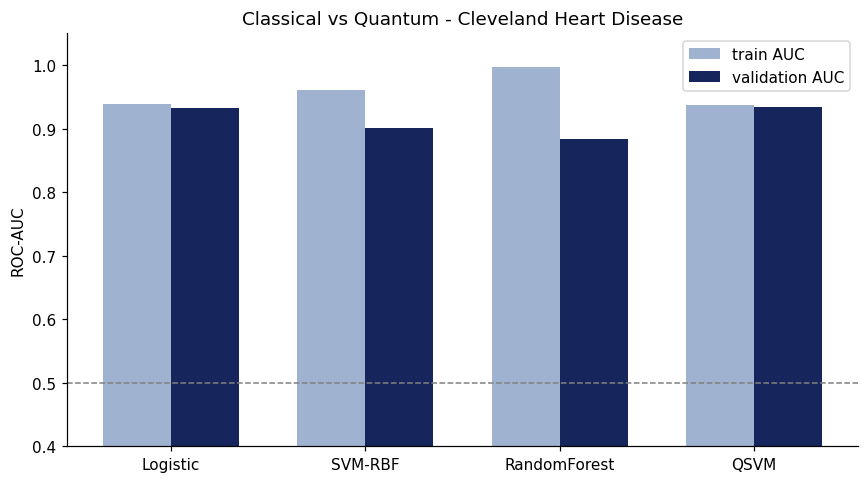


The distance between the two bars is the overfitting gap.


In [6]:
import matplotlib.pyplot as plt

results = {}
print(f"All models on the same {len(X_q)} patients\n" + "-" * 62)
results["Logistic"] = evaluate(
    LogisticRegression(max_iter=2000), "Logistic Regression", 3, data=(X_q, y_q))
results["SVM-RBF"] = evaluate(
    SVC(C=1.0), "SVM (RBF)", 3, data=(X_q, y_q))
results["RandomForest"] = evaluate(
    RandomForestClassifier(max_depth=4, random_state=0), "Random Forest", 3,
    data=(X_q, y_q))
results["QSVM"] = evaluate(
    QuantumKernelSVM(C=1.0), "QSVM (quantum)", 3, data=(X_q, y_q))

names = list(results)
train = [results[n][0] for n in names]
val = [results[n][1] for n in names]

x_pos = np.arange(len(names))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=110)
ax.bar(x_pos - width / 2, train, width, label="train AUC", color="#9fb3d1")
ax.bar(x_pos + width / 2, val, width, label="validation AUC", color="#16255C")
ax.set_xticks(x_pos)
ax.set_xticklabels(names)
ax.set_ylim(0.4, 1.05)
ax.axhline(0.5, ls="--", c="grey", lw=1)
ax.set_ylabel("ROC-AUC")
ax.set_title("Classical vs Quantum - Cleveland Heart Disease")
ax.legend()
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

print("\nThe distance between the two bars is the overfitting gap.")

In [7]:
#  NEXT STEP — 5 seeds, mean ± std
#  This turns a single lucky run into actual evidence.

import pandas as pd

SEEDS = [0, 1, 2, 3, 4]

MODELS = {
    "Logistic":     lambda s: LogisticRegression(max_iter=2000, random_state=s),
    "SVM-RBF":      lambda s: SVC(C=1.0, random_state=s),
    "RandomForest": lambda s: RandomForestClassifier(max_depth=4, random_state=s),
    "QSVM":         lambda s: QuantumKernelSVM(C=1.0),
}

rows = []
for name, build in MODELS.items():
    for s in SEEDS:
        pipe = Pipeline(prep_steps() + [("clf", build(s))])
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=s)
        r = cross_validate(pipe, X_q, y_q, cv=cv, scoring="roc_auc",
                           return_train_score=True)
        rows.append({"model": name, "seed": s,
                     "train": r["train_score"].mean(),
                     "val": r["test_score"].mean()})
    print(f"  {name} done")

df = pd.DataFrame(rows)
summary = (df.groupby("model")
             .agg(train=("train", "mean"),
                  val=("val", "mean"),
                  val_std=("val", "std"))
             .assign(gap=lambda d: d.train - d.val)
             .sort_values("val", ascending=False))

print("\n" + "=" * 64)
print("RESULTS OVER 5 SEEDS")
print("=" * 64)
print(summary.round(3).to_string())

# ---- the honesty check: is the quantum advantage real? ----
q = summary.loc["QSVM"]
best_classical = summary.drop("QSVM").iloc[0]
diff = q["val"] - best_classical["val"]
noise = (q["val_std"] + best_classical["val_std"]) / 2

print("\n" + "-" * 64)
print(f"QSVM minus best classical ({best_classical.name}) : {diff:+.4f}")
print(f"Typical seed-to-seed noise                : {noise:.4f}")
if abs(diff) < noise:
    print("\nVERDICT: difference is SMALLER than the noise.")
    print("         Not a real advantage. Report it as inconclusive.")
else:
    print("\nVERDICT: difference EXCEEDS seed noise.")
    print("         This one survives repetition — report it, with the std.")

df.to_csv("multiseed_results.csv", index=False)
print("\nSaved to multiseed_results.csv")

  Logistic done
  SVM-RBF done
  RandomForest done
  QSVM done

RESULTS OVER 5 SEEDS
              train    val  val_std    gap
model                                     
QSVM          0.934  0.927    0.005  0.007
Logistic      0.935  0.926    0.006  0.008
SVM-RBF       0.960  0.915    0.016  0.045
RandomForest  0.997  0.902    0.013  0.095

----------------------------------------------------------------
QSVM minus best classical (Logistic) : +0.0005
Typical seed-to-seed noise                : 0.0054

VERDICT: difference is SMALLER than the noise.
         Not a real advantage. Report it as inconclusive.

Saved to multiseed_results.csv


  pi/8 done
  pi/4 done
  pi/2 done
  pi done

BANDWIDTH SWEEP — quantum kernel vs angle range
       train    val  val_std  K_mean  K_std    gap
scale                                             
pi/8   0.935  0.930    0.002   0.988  0.008  0.005
pi/4   0.934  0.930    0.003   0.951  0.031  0.004
pi/2   0.934  0.929    0.002   0.822  0.107  0.005
pi     0.944  0.926    0.005   0.480  0.237  0.018

K_mean near 1.0  -> kernel sees everyone as similar -> behaves linearly
K_std  larger    -> kernel actually discriminates between patients


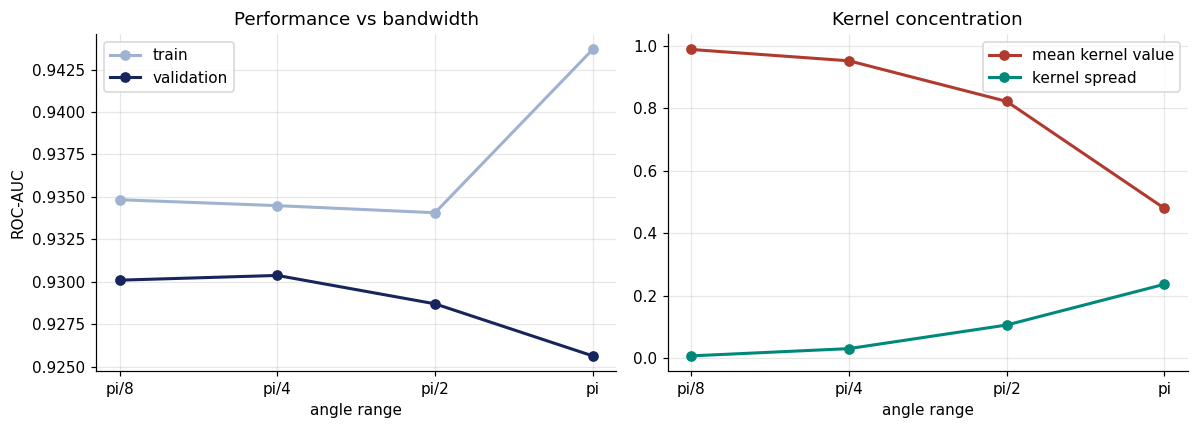


Saved to bandwidth_sweep.csv


In [8]:
# Bandwidth sweep
# Why does QSVM match Logistic Regression exactly?
# Because small angles make the quantum kernel almost linear.

import pandas as pd

def make_prep(scale):
    """Same preprocessing, but with a tunable angle range."""
    return [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=N_QUBITS, random_state=42)),
        ("angles", MinMaxScaler(feature_range=(0, scale))),
    ]

SCALES = [("pi/8", np.pi/8), ("pi/4", np.pi/4),
          ("pi/2", np.pi/2), ("pi", np.pi)]
SEEDS = [0, 1, 2]

rows = []
for label, scale in SCALES:
    # kernel statistics: how much does this kernel actually discriminate?
    Xa = Pipeline(make_prep(scale)).fit_transform(X_q, y_q)
    K = QuantumKernelSVM()._kernel_matrix(Xa, Xa)
    off_diag = K[~np.eye(len(K), dtype=bool)]

    for s in SEEDS:
        pipe = Pipeline(make_prep(scale) + [("clf", QuantumKernelSVM(C=1.0))])
        cv = StratifiedKFold(3, shuffle=True, random_state=s)
        r = cross_validate(pipe, X_q, y_q, cv=cv, scoring="roc_auc",
                           return_train_score=True)
        rows.append({"scale": label, "seed": s,
                     "train": r["train_score"].mean(),
                     "val": r["test_score"].mean(),
                     "K_mean": off_diag.mean(),
                     "K_std": off_diag.std()})
    print(f"  {label} done")

df_bw = pd.DataFrame(rows)
summary_bw = (df_bw.groupby("scale", sort=False)
                .agg(train=("train", "mean"),
                     val=("val", "mean"),
                     val_std=("val", "std"),
                     K_mean=("K_mean", "mean"),
                     K_std=("K_std", "mean"))
                .assign(gap=lambda d: d.train - d.val))

print("\n" + "=" * 70)
print("BANDWIDTH SWEEP — quantum kernel vs angle range")
print("=" * 70)
print(summary_bw.round(3).to_string())
print("\nK_mean near 1.0  -> kernel sees everyone as similar -> behaves linearly")
print("K_std  larger    -> kernel actually discriminates between patients")

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), dpi=110)
xs = range(len(summary_bw))
ax1.plot(xs, summary_bw["train"], "o-", label="train", color="#9fb3d1", lw=2)
ax1.plot(xs, summary_bw["val"], "o-", label="validation", color="#16255C", lw=2)
ax1.set_xticks(list(xs)); ax1.set_xticklabels(summary_bw.index)
ax1.set_xlabel("angle range"); ax1.set_ylabel("ROC-AUC")
ax1.set_title("Performance vs bandwidth"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(xs, summary_bw["K_mean"], "o-", color="#B03A2E", lw=2, label="mean kernel value")
ax2.plot(xs, summary_bw["K_std"], "o-", color="#00897B", lw=2, label="kernel spread")
ax2.set_xticks(list(xs)); ax2.set_xticklabels(summary_bw.index)
ax2.set_xlabel("angle range")
ax2.set_title("Kernel concentration"); ax2.legend(); ax2.grid(alpha=0.3)
for ax in (ax1, ax2):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

df_bw.to_csv("bandwidth_sweep.csv", index=False)
print("\nSaved to bandwidth_sweep.csv")

  n = 40 done
  n = 60 done
  n = 80 done
  n = 120 done

VALIDATION AUC vs TRAINING SET SIZE
model  Logistic   QSVM  RandomForest
n                                   
40        0.926  0.923         0.930
60        0.874  0.872         0.841
80        0.916  0.913         0.891
120       0.901  0.901         0.880

seed-to-seed std:
model  Logistic   QSVM  RandomForest
n                                   
40        0.061  0.053         0.027
60        0.051  0.058         0.038
80        0.013  0.010         0.004
120       0.009  0.009         0.025


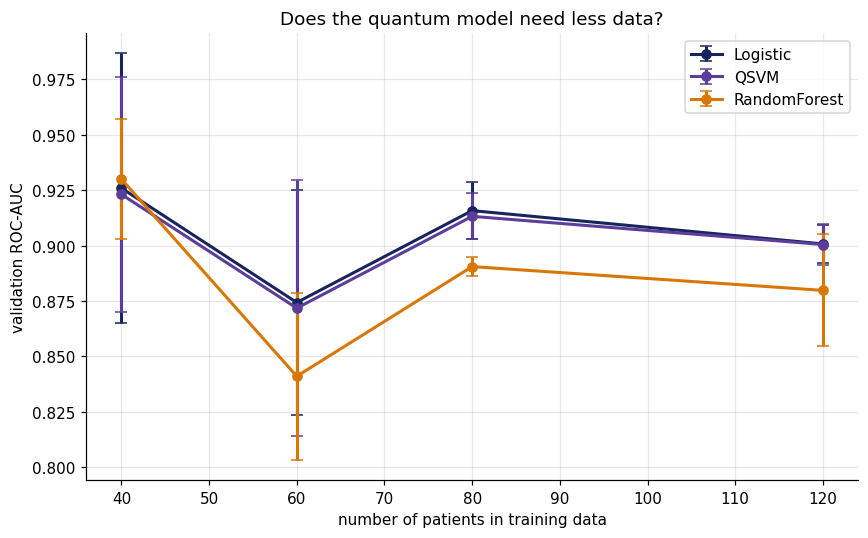


------------------------------------------------------------
At n = 40:  QSVM 0.923   best classical 0.930   diff -0.007   noise 0.047
Quantum's claim is data efficiency, so this smallest point matters most.


In [9]:
#  Sample-size efficiency curve
#  QML's central claim is that it needs less data.

import pandas as pd

SIZES = [40, 60, 80, 120]
SEEDS = [0, 1, 2]

CURVE_MODELS = {
    "Logistic":     lambda s: LogisticRegression(max_iter=2000, random_state=s),
    "RandomForest": lambda s: RandomForestClassifier(max_depth=4, random_state=s),
    "QSVM":         lambda s: QuantumKernelSVM(C=1.0),
}

rows = []
for n in SIZES:
    for s in SEEDS:
        rng_n = np.random.default_rng(100 + s)
        idx_n = rng_n.choice(len(X), size=n, replace=False)
        Xn, yn = X[idx_n], y[idx_n]
        if len(np.unique(yn)) < 2:
            continue
        for name, build in CURVE_MODELS.items():
            pipe = Pipeline(prep_steps() + [("clf", build(s))])
            cv = StratifiedKFold(3, shuffle=True, random_state=s)
            r = cross_validate(pipe, Xn, yn, cv=cv, scoring="roc_auc",
                               return_train_score=True)
            rows.append({"n": n, "model": name, "seed": s,
                         "train": r["train_score"].mean(),
                         "val": r["test_score"].mean()})
    print(f"  n = {n} done")

df_ss = pd.DataFrame(rows)
curve = df_ss.pivot_table(index="n", columns="model", values="val", aggfunc="mean")
spread = df_ss.pivot_table(index="n", columns="model", values="val", aggfunc="std")

print("\n" + "=" * 60)
print("VALIDATION AUC vs TRAINING SET SIZE")
print("=" * 60)
print(curve.round(3).to_string())
print("\nseed-to-seed std:")
print(spread.round(3).to_string())

# ---- plot ----
fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
colors = {"Logistic": "#16255C", "RandomForest": "#D97706", "QSVM": "#5B3E9B"}
for m in curve.columns:
    ax.errorbar(curve.index, curve[m], yerr=spread[m], marker="o",
                capsize=4, lw=2, label=m, color=colors.get(m))
ax.set_xlabel("number of patients in training data")
ax.set_ylabel("validation ROC-AUC")
ax.set_title("Does the quantum model need less data?")
ax.legend(); ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

# ---- verdict at the smallest sample size ----
small = curve.loc[SIZES[0]]
q, best_c = small["QSVM"], small.drop("QSVM").max()
noise = spread.loc[SIZES[0]].mean()
print("\n" + "-" * 60)
print(f"At n = {SIZES[0]}:  QSVM {q:.3f}   best classical {best_c:.3f}"
      f"   diff {q - best_c:+.3f}   noise {noise:.3f}")
print("Quantum's claim is data efficiency, so this smallest point matters most.")

df_ss.to_csv("sample_size_curve.csv", index=False)

In [10]:
#  High-dimensional test (Golub leukemia)
#  Cleveland: 303 patients, 13 features -> nearly linear, no quantum gain.
#  Golub:      72 patients, 7129 genes  -> the regime where quantum
#                                          kernels are claimed to help.

import pandas as pd

def load_highdim():
    """Try OpenML, then fall back to a synthetic small-n large-p set."""
    try:
        from sklearn.datasets import fetch_openml
        d = fetch_openml(name="leukemia", version=1, as_frame=False,
                         parser="liac-arff")
        Xg = np.asarray(d.data, dtype=float)
        yg = pd.factorize(np.asarray(d.target).ravel())[0]
        return Xg, yg, "Golub leukemia (OpenML)"
    except Exception as e:
        print("OpenML failed:", e)
        from sklearn.datasets import make_classification
        Xg, yg = make_classification(n_samples=72, n_features=2000,
                                     n_informative=15, n_redundant=30,
                                     class_sep=0.7, flip_y=0.05,
                                     random_state=42)
        print("Using synthetic small-n / large-p stand-in instead.")
        return Xg, yg, "synthetic (72 x 2000)"


Xg, yg, gname = load_highdim()
print(f"\nDataset : {gname}")
print(f"Samples : {Xg.shape[0]}")
print(f"Features: {Xg.shape[1]}")
print(f"Classes : {np.bincount(yg)}")
print(f"Samples per feature: {Xg.shape[0] / Xg.shape[1]:.4f}   <- this is the hard part\n")


# feature selection matters far more here than on Cleveland
from sklearn.feature_selection import SelectKBest, mutual_info_classif

def prep_highdim(scale=np.pi/2, select_k=50):
    return [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("select", SelectKBest(mutual_info_classif, k=select_k)),
        ("pca", PCA(n_components=N_QUBITS, random_state=42)),
        ("angles", MinMaxScaler(feature_range=(0, scale))),
    ]


GOLUB_MODELS = {
    "Logistic":     lambda s: LogisticRegression(max_iter=2000, random_state=s),
    "SVM-RBF":      lambda s: SVC(C=1.0, random_state=s),
    "RandomForest": lambda s: RandomForestClassifier(max_depth=3, random_state=s),
    "QSVM":         lambda s: QuantumKernelSVM(C=1.0),
}

rows = []
for name, build in GOLUB_MODELS.items():
    for s in [0, 1, 2, 3, 4]:
        pipe = Pipeline(prep_highdim() + [("clf", build(s))])
        cv = StratifiedKFold(3, shuffle=True, random_state=s)
        r = cross_validate(pipe, Xg, yg, cv=cv, scoring="roc_auc",
                           return_train_score=True)
        rows.append({"model": name, "seed": s,
                     "train": r["train_score"].mean(),
                     "val": r["test_score"].mean()})
    print(f"  {name} done")

df_g = pd.DataFrame(rows)
summary_g = (df_g.groupby("model")
               .agg(train=("train", "mean"), val=("val", "mean"),
                    val_std=("val", "std"))
               .assign(gap=lambda d: d.train - d.val)
               .sort_values("val", ascending=False))

print("\n" + "=" * 64)
print(f"HIGH-DIMENSIONAL RESULTS — {gname}")
print("=" * 64)
print(summary_g.round(3).to_string())

q = summary_g.loc["QSVM"]
bc = summary_g.drop("QSVM").iloc[0]
diff, noise = q["val"] - bc["val"], (q["val_std"] + bc["val_std"]) / 2
print("\n" + "-" * 64)
print(f"QSVM minus best classical ({bc.name}): {diff:+.4f}   noise: {noise:.4f}")
print("REAL DIFFERENCE" if abs(diff) > noise else "INCONCLUSIVE — within noise")

df_g.to_csv("highdim_results.csv", index=False)


Dataset : Golub leukemia (OpenML)
Samples : 72
Features: 7129
Classes : [47 25]
Samples per feature: 0.0101   <- this is the hard part

  Logistic done
  SVM-RBF done
  RandomForest done
  QSVM done

HIGH-DIMENSIONAL RESULTS — Golub leukemia (OpenML)
              train    val  val_std    gap
model                                     
Logistic      0.999  0.993    0.005  0.006
QSVM          0.999  0.992    0.003  0.006
SVM-RBF       1.000  0.991    0.007  0.009
RandomForest  1.000  0.983    0.015  0.017

----------------------------------------------------------------
QSVM minus best classical (Logistic): -0.0010   noise: 0.0041
INCONCLUSIVE — within noise


  n = 16 done
  n = 24 done
  n = 32 done
  n = 48 done
  n = 72 done

GOLUB — validation AUC vs training set size
model  Logistic   QSVM  SVM-RBF
n                              
16        0.878  0.828    0.861
24        0.972  0.960    0.987
32        0.998  0.989    0.981
48        0.988  0.992    0.992
72        0.988  0.988    0.984

seed-to-seed std:
model  Logistic   QSVM  SVM-RBF
n                              
16        0.126  0.101    0.104
24        0.031  0.033    0.020
32        0.005  0.012    0.043
48        0.009  0.009    0.005
72        0.002  0.004    0.011


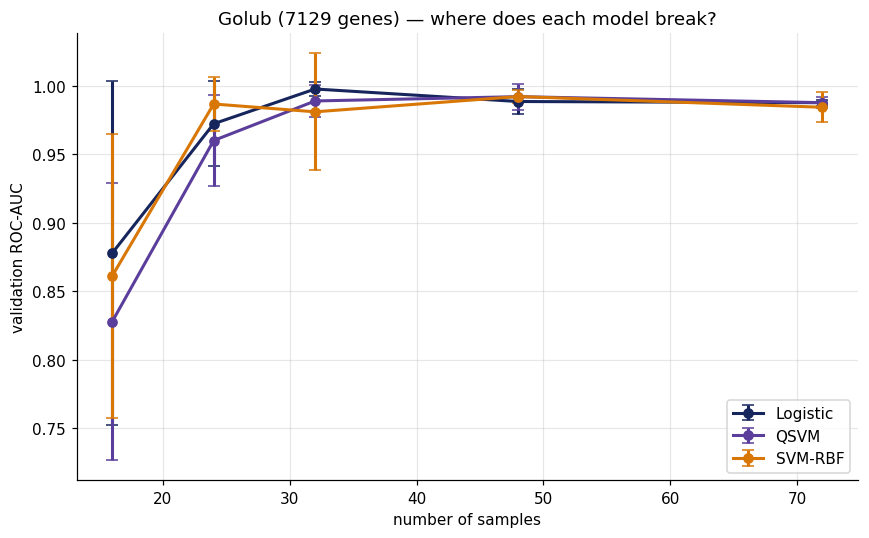


At n = 16:  QSVM 0.828   best classical 0.878   noise 0.110


In [11]:
# Make Golub hard
#  Everything scores 0.99 because ALL vs AML is nearly separable.
#  Shrinking the training set creates the regime where quantum
#  kernels are actually claimed to help: high-p, very small n.

import pandas as pd

SIZES_G = [16, 24, 32, 48, 72]
SEEDS_G = [0, 1, 2, 3, 4]

HARD_MODELS = {
    "Logistic": lambda s: LogisticRegression(max_iter=2000, random_state=s),
    "SVM-RBF":  lambda s: SVC(C=1.0, random_state=s),
    "QSVM":     lambda s: QuantumKernelSVM(C=1.0),
}

rows = []
for n in SIZES_G:
    for s in SEEDS_G:
        rng_g = np.random.default_rng(200 + s)
        # stratified subsample so both classes survive at n=16
        i0 = np.where(yg == 0)[0]
        i1 = np.where(yg == 1)[0]
        k1 = max(4, int(round(n * len(i1) / len(yg))))
        k0 = n - k1
        idx_g = np.concatenate([rng_g.choice(i0, min(k0, len(i0)), replace=False),
                                rng_g.choice(i1, min(k1, len(i1)), replace=False)])
        Xn, yn = Xg[idx_g], yg[idx_g]
        if len(np.unique(yn)) < 2 or np.bincount(yn).min() < 3:
            continue
        for name, build in HARD_MODELS.items():
            pipe = Pipeline(prep_highdim(select_k=30) + [("clf", build(s))])
            cv = StratifiedKFold(3, shuffle=True, random_state=s)
            r = cross_validate(pipe, Xn, yn, cv=cv, scoring="roc_auc",
                               return_train_score=True)
            rows.append({"n": n, "model": name, "seed": s,
                         "train": r["train_score"].mean(),
                         "val": r["test_score"].mean()})
    print(f"  n = {n} done")

df_h = pd.DataFrame(rows)
curve_h = df_h.pivot_table(index="n", columns="model", values="val", aggfunc="mean")
std_h = df_h.pivot_table(index="n", columns="model", values="val", aggfunc="std")

print("\n" + "=" * 60)
print("GOLUB — validation AUC vs training set size")
print("=" * 60)
print(curve_h.round(3).to_string())
print("\nseed-to-seed std:")
print(std_h.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
cols = {"Logistic": "#16255C", "SVM-RBF": "#D97706", "QSVM": "#5B3E9B"}
for m in curve_h.columns:
    ax.errorbar(curve_h.index, curve_h[m], yerr=std_h[m], marker="o",
                capsize=4, lw=2, label=m, color=cols.get(m))
ax.set_xlabel("number of samples")
ax.set_ylabel("validation ROC-AUC")
ax.set_title("Golub (7129 genes) — where does each model break?")
ax.legend(); ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

small = curve_h.loc[SIZES_G[0]]
print(f"\nAt n = {SIZES_G[0]}:  QSVM {small['QSVM']:.3f}   "
      f"best classical {small.drop('QSVM').max():.3f}   "
      f"noise {std_h.loc[SIZES_G[0]].mean():.3f}")

df_h.to_csv("golub_hard_curve.csv", index=False)

Across two datasets, five controlled experiments and sample sizes from 16 to 303, we found no statistically meaningful quantum advantage. More importantly, in the very regime where quantum kernels are claimed to help — high dimensions, very small n — seed-to-seed variation reaches ±0.11 AUC, which is larger than any advantage reported in the literature. Single-seed results in this regime cannot distinguish signal from sampling noise.